In [1]:
# Imports and shared scoring helpers
import pandas as pd
import numpy as np
from insights_utils import ( generate_specter_embeddings, compute_stylometric_features,
get_catboost_proba, compute_divergence_scores, compute_entropy)
import re
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

In [2]:
# Load LiveIdeaBench: ideas + their LLM-judge ratings (originality, feasibility, clarity, fluency, avg)
ds = pd.read_csv(r"data/liveideabench_hf.csv"
                 ,usecols=["keywords","idea","avg","originality","feasibility","clarity","fluency"]).dropna()

In [3]:
# Preview the raw LiveIdeaBench dataset
ds.head()

,keywords,idea,originality,feasibility,clarity,fluency,avg
0,ecodesign,**Idea:** **Problem:** Current ecodesign relie...,8.0,6.0,8.0,4.0,6.50
1,ecodesign,**Idea:** **Problem:** Current ecodesign relie...,7.0,6.0,8.0,4.0,6.25
2,ecodesign,**Idea:** **Problem:** Current ecodesign relie...,9.0,6.0,9.0,4.0,7.00
3,civil engineering,**Background:** Aging civil infrastructure fac...,7.0,6.0,9.0,4.0,6.50
4,civil engineering,**Background:** Aging civil infrastructure fac...,8.0,6.0,7.0,4.0,6.25


In [4]:
# ~281k rows = same idea rated multiple times by different raters
ds.shape

(281090, 7)

In [5]:
# Collapse to one row per idea: mean of each rating + count of raters
ds_grouped = (
    ds.groupby("idea")
    .agg(keywords=("keywords", "first"), avg_score=("avg", "mean"), count=("avg", "count")
         ,originality=("originality", "mean"), feasibility=("feasibility", "mean"), clarity=("clarity", "mean"), fluency=("fluency", "mean"))
    .reset_index()
)


In [6]:
# Keep only ideas rated by more than 2 raters (more reliable average)
ds_grouped = ds_grouped[ds_grouped["count"] > 2].reset_index(drop=True)

In [7]:
# Row count after filtering by rater coverage
ds_grouped.shape

(93532, 8)

In [8]:
# Helper: flag a string as English if >=80% of chars are A–Z/a–z
def is_english(text,t=0.8):
    if not isinstance(text, str) or len(text) == 0:
        return False
    english_chars = re.findall(r'[A-Za-z]', text)
    return len(english_chars) / len(text) > t

In [9]:
# Drop non-English ideas
ds_grouped=ds_grouped[ds_grouped["idea"].apply(is_english)]

In [10]:
# Row count after English filter
ds_grouped.shape

(93081, 8)

In [11]:
# Spot-check the tail to confirm filters look right
ds_grouped.tail()

,idea,keywords,avg_score,count,originality,feasibility,clarity,fluency
93508,xray diffraction is a crucial technique for el...,xray diffraction,7.166667,3,7.666667,6.000000,8.000000,7.0
93509,"échelle Metastasis, the spread of cancer, rema...",metastasis,6.666667,3,8.000000,5.000000,6.666667,7.0
93510,زد ## Project: Decentralized Secure Data Shari...,information technology,5.750000,3,4.666667,5.333333,6.000000,7.0
93511,“Smart Wound Bioelectronics: Develop a flexibl...,bioelectronics,7.750000,3,7.666667,5.333333,8.000000,10.0
93513,。 **Superfluid cooling for sensitive detectors...,superfluidity,6.750000,3,6.000000,4.666667,6.333333,10.0


In [12]:
# Summary stats on LLM-judge ratings — gives a feel for the scoring distribution
ds_grouped.describe()

,avg_score,count,originality,feasibility,clarity,fluency
count,93081.000000,93081.0,93081.000000,93081.000000,93081.000000,93081.000000
mean,6.751539,3.0,7.165460,5.859182,7.557301,6.424211
std,0.776507,0.0,0.845648,1.071003,0.846570,2.530662
min,1.916667,3.0,0.666667,0.666667,1.000000,1.000000
25%,6.250000,3.0,6.666667,5.333333,7.000000,4.000000
50%,6.750000,3.0,7.333333,6.000000,7.666667,7.000000
75%,7.333333,3.0,7.666667,6.666667,8.000000,7.000000
max,9.000000,3.0,9.333333,10.000000,10.000000,10.000000


In [13]:
# List every keyword so we can decide which to group into categories
for keyword in list(ds_grouped["keywords"].unique()):   
    print(keyword)

environmental microbiology
sonar
mechanics
food chain
epidemic modeling
planetary science
atomic physics
calvin cycle
genetics
biomass energy
one health
protein folding
reinforcement learning
satellite technology
parallel computing
safety protocols
aerodynamics
evolutionary computation
space debris
orbital mechanics
nuclear engineering
rna transcription
marine biology
antibiotic stewardship
antimicrobial resistance
keplers laws
entropy
higgs boson
percolation theory
mendelian genetics
geomicrobiology
primatology
kin selection
comets
asteroid deflection
astrogeology
astrometry
astrostatistics
distillation
augmented cognition
software engineering
mining engineering
biosensors
scientific literacy
mammals
paleomagnetism
petrology
statistical physics
cosmic inflation
ballistics
biomimetics
bioplastics
complex analysis
warp drives
cern
chemical engineering
crisprcas9
cell differentiation
circadian rhythms
citation analysis
cloud physics
cognitive robotics
collective intelligence
comparative 

In [14]:
# Hand-curated keyword -> high-level category map (used for stratified analysis)
hmap = {
    "CORE AI / ML / CS":{
                    "reinforcement learning",
                    "unsupervised learning",
                    "support vector machines",
                    "hierarchical clustering",
                    "neural engineering",
                    "neuromorphic computing",
                    "computational social science",
                    "information retrieval"
                },
    "NETWORKS & COMPLEX SYSTEMS":{
                    "network theory",
                    "network science",
                    "social network analysis",
                    "complex systems",
                    "nonlinear dynamics",
                    "stochastic processes",
                    "graph theory"
                },
    "AI X BIO":{
                        "computational biology",
                        "bioinformatics algorithms",
                        "gene expression",
                        "protein folding",
                        "epigenetics",
                        "transcriptomics",
                        "systems biology",
                        "microbiome",
                        "cognitive neuroscience"
                    },
    "AI X PHYSICS":{
                        "astrophysics",
                        "cosmology",
                        "exoplanet detection",
                        "gravitational waves",
                        "astroinformatics"
                    },
    "AI X ENVIRONMENT":{
                        "climate models",
                        "environmental dna",
                        "ecosystem ecology"
                        }
}

In [15]:
# Verify every keyword in hmap actually appears in the data; tally ideas per category
missing = 0
category_counts = {k: 0 for k in hmap.keys()}
for k, v in hmap.items():
    for keyword in v:
        if keyword not in ds_grouped["keywords"].values:
            print(f"Missing keyword: {keyword} in category: {k}")
            missing += 1
        else:
            category_counts[k] += ds_grouped[ds_grouped["keywords"] == keyword].shape[0]
print(f"Total missing keywords: {missing}")


Total missing keywords: 0


In [16]:
# Show per-category counts and ratios — confirms category balance
print("Category counts:", category_counts)
total_count = sum(category_counts.values())
print(total_count)
for k, v in category_counts.items():
    ratio = v / total_count if total_count > 0 else 0
    print(f"Category: {k}, Count: {v}, Ratio: {ratio:.2%}")

Category counts: {'CORE AI / ML / CS': 628, 'NETWORKS & COMPLEX SYSTEMS': 546, 'AI X BIO': 708, 'AI X PHYSICS': 398, 'AI X ENVIRONMENT': 239}
2519
Category: CORE AI / ML / CS, Count: 628, Ratio: 24.93%
Category: NETWORKS & COMPLEX SYSTEMS, Count: 546, Ratio: 21.68%
Category: AI X BIO, Count: 708, Ratio: 28.11%
Category: AI X PHYSICS, Count: 398, Ratio: 15.80%
Category: AI X ENVIRONMENT, Count: 239, Ratio: 9.49%


In [17]:
# Keep only ideas whose keyword is in the curated category map
filtered_live_df = ds_grouped[ds_grouped["keywords"].isin([kw for kws in hmap.values() for kw in kws])]

In [18]:
# Attach the high-level category for each idea
filtered_live_df["category"] = filtered_live_df["keywords"].apply(lambda kw: next((k for k, v in hmap.items() if kw in v), pd.NA)).copy()

In [19]:
# Assign a clean sequential id for downstream merges
filtered_live_df["id"] = np.arange(len(filtered_live_df))

In [20]:
# Final filtered set: ~2.5k ideas across 5 categories
filtered_live_df.shape

(2519, 10)

In [21]:
# Sanity check: every idea is unique (no duplicate text)
filtered_live_df["idea"].unique().shape

(2519,)

In [22]:
# Spot-check the filtered ideas
filtered_live_df.tail()

,idea,keywords,avg_score,count,originality,feasibility,clarity,fluency,category,id
93249,\n**Idea: Manifold-based Early Warning Signals...,nonlinear dynamics,6.583333,3,7.666667,7.333333,7.333333,4.0,NETWORKS & COMPLEX SYSTEMS,2514
93261,\n**Idea:** Gravitational wave (GW) detectors ...,gravitational waves,7.166667,3,7.333333,6.333333,8.000000,7.0,AI X PHYSICS,2515
93303,\n\n**Background**: Hierarchical clustering or...,hierarchical clustering,7.583333,3,8.000000,7.000000,8.333333,7.0,CORE AI / ML / CS,2516
93472,eDNA Sentinel Network: Develop an IoT-integrat...,environmental dna,6.500000,3,8.000000,6.000000,8.000000,4.0,AI X ENVIRONMENT,2517
93488,my idea is to leverage neuromorphic computing ...,neuromorphic computing,7.666667,3,8.000000,5.333333,7.333333,10.0,CORE AI / ML / CS,2518


In [23]:
# Confirm all 5 categories are present
filtered_live_df["category"].unique()

array(['AI X BIO', 'CORE AI / ML / CS', 'NETWORKS & COMPLEX SYSTEMS',
       'AI X ENVIRONMENT', 'AI X PHYSICS'], dtype=object)

In [24]:
# Keep only the columns needed
feature_df = filtered_live_df[["id", "category","idea","avg_score",
                               "originality","feasibility","clarity","fluency"]].copy()

In [25]:
# Inspect feature_df
feature_df

,id,category,idea,avg_score,originality,feasibility,clarity,fluency
11,0,AI X BIO,"""**Protein Folding Acceleration using Intrinsi...",7.750000,6.666667,7.000000,7.333333,10.0
12,1,CORE AI / ML / CS,"""**Reinforcement Learning with Hierarchical Te...",6.250000,7.000000,5.000000,6.000000,7.0
111,2,AI X BIO,"""Develop a CRISPR-based optical tool for dynam...",7.500000,7.666667,6.666667,8.666667,7.0
129,3,CORE AI / ML / CS,"""Develop a computational model using social ne...",7.333333,7.000000,7.000000,8.333333,7.0
139,4,AI X BIO,"""Develop a dynamic systems biology model to an...",7.250000,7.666667,6.000000,8.333333,7.0
...,...,...,...,...,...,...,...,...
93249,2514,NETWORKS & COMPLEX SYSTEMS,\n**Idea: Manifold-based Early Warning Signals...,6.583333,7.666667,7.333333,7.333333,4.0
93261,2515,AI X PHYSICS,\n**Idea:** Gravitational wave (GW) detectors ...,7.166667,7.333333,6.333333,8.000000,7.0
93303,2516,CORE AI / ML / CS,\n\n**Background**: Hierarchical clustering or...,7.583333,8.000000,7.000000,8.333333,7.0
93472,2517,AI X ENVIRONMENT,eDNA Sentinel Network: Develop an IoT-integrat...,6.500000,8.000000,6.000000,8.000000,4.0


In [26]:
# Attach 768-dim SPECTER embeddings of each idea text
feature_df = pd.merge(
    feature_df,
    generate_specter_embeddings(feature_df, text_col="idea", id_col="id"),
    on="id",
    how="inner"
)

Loaded model: specter


In [27]:
# Preview feature_df with embeddings attached
feature_df

,id,category,idea,avg_score,originality,feasibility,clarity,fluency,specter_embedding_0,specter_embedding_1,...,specter_embedding_758,specter_embedding_759,specter_embedding_760,specter_embedding_761,specter_embedding_762,specter_embedding_763,specter_embedding_764,specter_embedding_765,specter_embedding_766,specter_embedding_767
0,0,AI X BIO,"""**Protein Folding Acceleration using Intrinsi...",7.750000,6.666667,7.000000,7.333333,10.0,0.325068,1.218334,...,0.905776,-0.828133,1.286240,0.508265,-0.381403,0.202983,0.027230,-0.423314,-0.121436,0.880489
1,1,CORE AI / ML / CS,"""**Reinforcement Learning with Hierarchical Te...",6.250000,7.000000,5.000000,6.000000,7.0,-0.160453,-0.372891,...,0.603663,-0.150029,0.708467,0.362810,0.195468,-0.439371,-0.114556,0.325234,-0.163779,1.200275
2,2,AI X BIO,"""Develop a CRISPR-based optical tool for dynam...",7.500000,7.666667,6.666667,8.666667,7.0,0.063332,0.797574,...,0.581706,-0.498760,1.687707,-0.133855,-0.046164,-0.169625,-0.360802,0.004763,-0.958819,0.148628
3,3,CORE AI / ML / CS,"""Develop a computational model using social ne...",7.333333,7.000000,7.000000,8.333333,7.0,-0.538907,-0.219662,...,0.370359,-1.664658,0.898278,0.627956,0.260450,-0.279815,0.311432,0.114559,0.707135,1.253266
4,4,AI X BIO,"""Develop a dynamic systems biology model to an...",7.250000,7.666667,6.000000,8.333333,7.0,-0.082721,0.651112,...,0.249628,-0.221380,0.429279,0.196937,0.605232,-0.004366,0.107072,0.276409,0.587318,-0.205732
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2514,2514,NETWORKS & COMPLEX SYSTEMS,\n**Idea: Manifold-based Early Warning Signals...,6.583333,7.666667,7.333333,7.333333,4.0,-0.237257,0.816602,...,0.673150,0.070342,1.490045,0.722815,0.195839,-0.527111,0.804731,-0.393790,-0.060580,0.026036
2515,2515,AI X PHYSICS,\n**Idea:** Gravitational wave (GW) detectors ...,7.166667,7.333333,6.333333,8.000000,7.0,-0.938511,0.483796,...,1.035922,-0.568861,1.374882,0.303588,0.154778,0.096889,0.005311,0.526889,-0.246141,0.338574
2516,2516,CORE AI / ML / CS,\n\n**Background**: Hierarchical clustering or...,7.583333,8.000000,7.000000,8.333333,7.0,0.068921,0.162827,...,0.164884,-0.591045,0.935864,0.010758,0.176163,-0.146616,-0.044322,-0.035158,0.428198,-0.440809
2517,2517,AI X ENVIRONMENT,eDNA Sentinel Network: Develop an IoT-integrat...,6.500000,8.000000,6.000000,8.000000,4.0,-0.255430,-0.456174,...,0.577950,-0.899852,0.477375,1.003713,-0.141508,-0.749233,-0.082873,-0.826156,-0.639183,-0.162323


In [28]:
# Compute and attach stylometric features (word/sentence stats, lexical diversity, etc.)
stylometric_df = feature_df["idea"].apply(compute_stylometric_features)
feature_df = pd.concat([feature_df, stylometric_df], axis=1)

In [29]:
# Summary stats on stylometric features — sanity check ranges
stylometric_df.describe()

,word_count,sentence_count,avg_word_length,avg_sentence_length,lexical_diversity,complex_word_ratio
count,2519.000000,2519.000000,2519.000000,2519.000000,2519.000000,2519.000000
mean,92.789996,5.204843,6.482393,18.938865,0.826086,0.508898
std,20.968280,1.867993,0.389555,4.515657,0.054896,0.064666
min,26.000000,1.000000,4.807692,6.692308,0.455000,0.294118
25%,81.000000,4.000000,6.231174,16.166667,0.791667,0.466978
50%,94.000000,5.000000,6.468750,18.888889,0.827957,0.510000
75%,103.000000,6.000000,6.725130,21.750000,0.862500,0.550592
max,201.000000,17.000000,7.985714,53.000000,0.979167,0.714286


In [30]:
# Confirm no duplicate idea texts before scoring
feature_df[["idea"]].duplicated().sum()

np.int64(0)

In [31]:
# Preview feature_df

feature_df.head()

,id,category,idea,avg_score,originality,feasibility,clarity,fluency,specter_embedding_0,specter_embedding_1,...,specter_embedding_764,specter_embedding_765,specter_embedding_766,specter_embedding_767,word_count,sentence_count,avg_word_length,avg_sentence_length,lexical_diversity,complex_word_ratio
0,0,AI X BIO,"""**Protein Folding Acceleration using Intrinsi...",7.750000,6.666667,7.000000,7.333333,10.0,0.325068,1.218334,...,0.027230,-0.423314,-0.121436,0.880489,76.0,6.0,6.210526,12.666667,0.763158,0.486842
1,1,CORE AI / ML / CS,"""**Reinforcement Learning with Hierarchical Te...",6.250000,7.000000,5.000000,6.000000,7.0,-0.160453,-0.372891,...,-0.114556,0.325234,-0.163779,1.200275,53.0,4.0,6.056604,13.250000,0.886792,0.433962
2,2,AI X BIO,"""Develop a CRISPR-based optical tool for dynam...",7.500000,7.666667,6.666667,8.666667,7.0,0.063332,0.797574,...,-0.360802,0.004763,-0.958819,0.148628,97.0,6.0,6.474227,16.166667,0.752577,0.515464
3,3,CORE AI / ML / CS,"""Develop a computational model using social ne...",7.333333,7.000000,7.000000,8.333333,7.0,-0.538907,-0.219662,...,0.311432,0.114559,0.707135,1.253266,64.0,4.0,6.312500,16.000000,0.796875,0.484375
4,4,AI X BIO,"""Develop a dynamic systems biology model to an...",7.250000,7.666667,6.000000,8.333333,7.0,-0.082721,0.651112,...,0.107072,0.276409,0.587318,-0.205732,125.0,6.0,6.456000,20.833333,0.656000,0.544000


In [32]:
# Value score: CatBoost predicted citation-worthiness for each idea
feature_df['catboost_proba'] = get_catboost_proba(feature_df)

In [33]:
# Divergence score: distance from nearest neighbors in the internal SPECTER corpus
feature_df["divergence"] = compute_divergence_scores(feature_df)

FAISS index built with 131772 vectors of dimension 768


In [34]:
# Entropy score
feature_df["entropy"] = feature_df["idea"].apply(compute_entropy)

Loaded model: gpt2-medium


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model for gpt2-medium
Using cached model f

In [35]:
# Quick look at the entropy values
feature_df["entropy"]

0       3.908447
1       3.448062
2       3.317753
3       3.101593
4       3.159751
          ...   
2514    3.767901
2515    4.198398
2516    3.964001
2517    4.284258
2518    3.072317
Name: entropy, Length: 2519, dtype: float64

In [36]:
# Persist the slim feature set (ids + ratings + 3 scores) for downstream analysis
feature_df[['id',
 'category',
 'idea','avg_score','catboost_proba',
 'divergence','originality','feasibility','clarity','fluency',
 'entropy']].to_csv(r"data/liveidea_filtered.csv", index=False)

In [37]:
# Reload slim feature set from disk (analysis starts here, decoupled from scoring above)
feature_df = pd.read_csv(r"data/liveidea_filtered.csv")

In [38]:
# Preview feature_df
feature_df.head()

,id,category,idea,avg_score,catboost_proba,divergence,originality,feasibility,clarity,fluency,entropy
0,0,AI X BIO,"""**Protein Folding Acceleration using Intrinsi...",7.750000,0.262814,0.206471,6.666667,7.000000,7.333333,10.0,3.908447
1,1,CORE AI / ML / CS,"""**Reinforcement Learning with Hierarchical Te...",6.250000,0.466407,0.146959,7.000000,5.000000,6.000000,7.0,3.448062
2,2,AI X BIO,"""Develop a CRISPR-based optical tool for dynam...",7.500000,0.154327,0.235459,7.666667,6.666667,8.666667,7.0,3.317753
3,3,CORE AI / ML / CS,"""Develop a computational model using social ne...",7.333333,0.300237,0.138431,7.000000,7.000000,8.333333,7.0,3.101593
4,4,AI X BIO,"""Develop a dynamic systems biology model to an...",7.250000,0.339143,0.183009,7.666667,6.000000,8.333333,7.0,3.159751


In [39]:
# Distribution of the 3 model-derived scores
print("Shape:", feature_df.shape)
print(feature_df[['catboost_proba','divergence','entropy']].describe())

Shape: (2519, 11)
       catboost_proba   divergence      entropy
count     2519.000000  2519.000000  2519.000000
mean         0.341634     0.182582     3.392403
std          0.125373     0.042061     0.385639
min          0.038101     0.091290     2.286542
25%          0.247351     0.152207     3.110573
50%          0.334044     0.180016     3.367230
75%          0.429992     0.208937     3.652834
max          0.725541     0.351856     4.902291


In [40]:
# Helper: z-score normalization
def zscore(x):
    return (x - x.mean()) / x.std()

In [41]:
# Z-score the 3 model scores so they're on a comparable scale
feature_df["value_z"] = zscore(feature_df["catboost_proba"])
feature_df["div_z"] = zscore(feature_df["divergence"])
feature_df["entropy_z"] = zscore(feature_df["entropy"])

In [42]:
# Helper
def corr_with_p(x, y):
    rho, p = spearmanr(x, y)
    return rho, p

In [43]:
# Helper: 95% bootstrap CI for Spearman rho
def bootstrap_ci(x, y, n_boot=1000):
    vals = []
    n = len(x)
    for _ in range(n_boot):
        idx = np.random.choice(n, n, replace=True)
        rho, _ = spearmanr(x[idx], y[idx])
        vals.append(rho)
    return np.percentile(vals, [2.5, 97.5])

In [44]:
# Pairwise correlations among value / divergence / entropy with bootstrap CIs
pairs = [
    ("value_z", "entropy_z"),
    ("value_z", "div_z"),
    ("entropy_z", "div_z"),
]

results = []

for x, y in pairs:
    rho, p = corr_with_p(feature_df[x], feature_df[y])
    ci_low, ci_high = bootstrap_ci(feature_df[x].values, feature_df[y].values)
    
    results.append({
        "pair": f"{x} vs {y}",
        "rho": rho,
        "p_value": p,
        "CI_low": ci_low,
        "CI_high": ci_high
    })

corr_df = pd.DataFrame(results)
corr_df

,pair,rho,p_value,CI_low,CI_high
0,value_z vs entropy_z,-0.114761,7.646494e-09,-0.150573,-0.076442
1,value_z vs div_z,-0.508824,5.407143e-166,-0.541057,-0.476731
2,entropy_z vs div_z,0.139987,1.699156e-12,0.100112,0.176235


In [45]:
# Spearman correlation among the three z-scored model scores
corr_matrix = feature_df[["value_z","entropy_z","div_z"]].corr(method="spearman")
corr_matrix

,value_z,entropy_z,div_z
value_z,1.000000,-0.114761,-0.508824
entropy_z,-0.114761,1.000000,0.139987
div_z,-0.508824,0.139987,1.000000


In [46]:
# Helper: scatter plot with rho + p in the title
def scatter_plot(x, y, xlabel, ylabel):
    rho, p = spearmanr(x, y)
    
    plt.figure(figsize=(6,5))
    plt.scatter(x, y, alpha=0.5)
    
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    
    plt.title(f"{xlabel} vs {ylabel}\nρ={rho:.3f}, p={p:.3f}")
    plt.grid(True)
    
    plt.show()

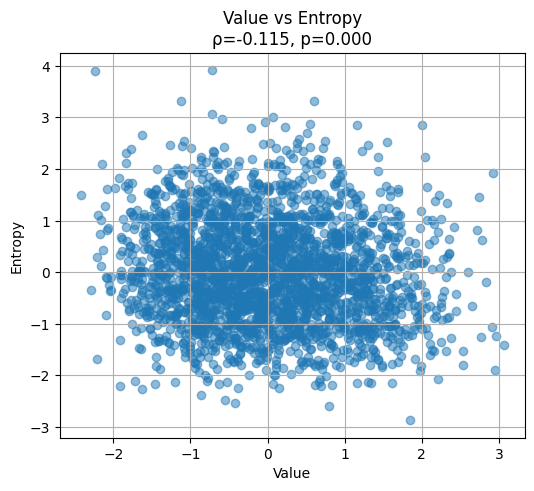

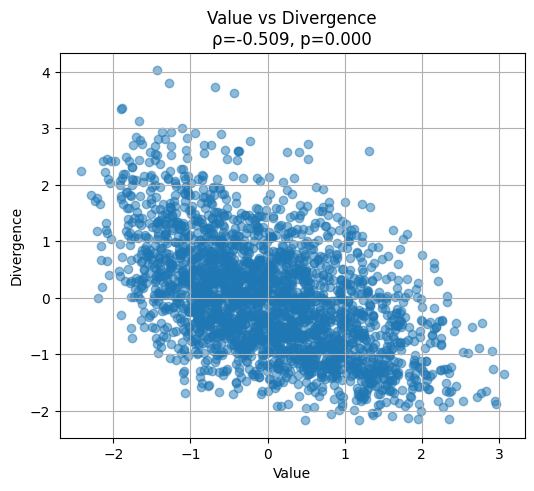

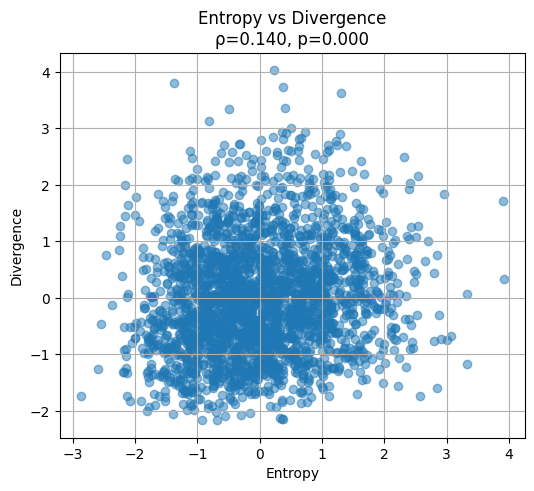

In [47]:
# Scatter plots for the 3 score pairs above (visual check of the correlations)
scatter_plot(feature_df["value_z"], feature_df["entropy_z"], "Value", "Entropy")
scatter_plot(feature_df["value_z"], feature_df["div_z"], "Value", "Divergence")
scatter_plot(feature_df["entropy_z"], feature_df["div_z"], "Entropy", "Divergence")

In [48]:
#Helper: histogram of a single column
def plot_distribution(x, title):
    plt.figure(figsize=(6,4))
    plt.hist(x, bins=40)
    plt.title(title)
    plt.xlabel(title)
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()

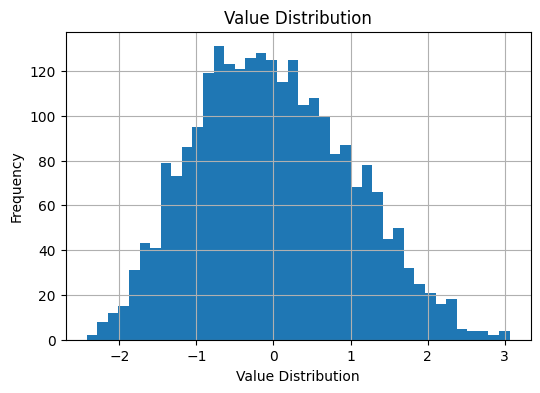

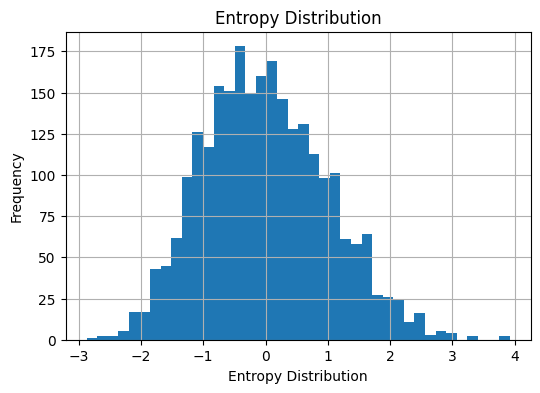

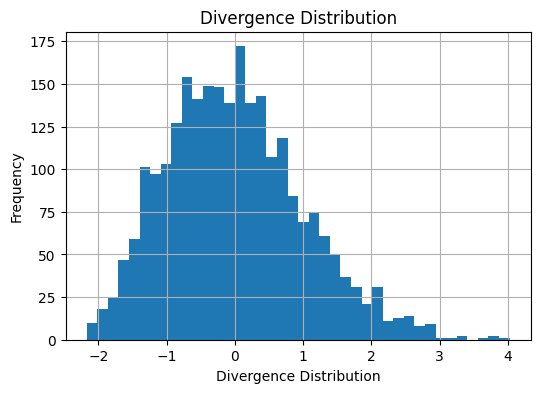

In [49]:
# Distributions of the 3 z-scored model signals
plot_distribution(feature_df["value_z"], "Value Distribution")
plot_distribution(feature_df["entropy_z"], "Entropy Distribution")
plot_distribution(feature_df["div_z"], "Divergence Distribution")

In [50]:
# Helper: winsorize columns to their 1st/99th percentiles

def clip_df(df, cols):
    df_clipped = df.copy()
    for col in cols:
        low = df[col].quantile(0.01)
        high = df[col].quantile(0.99)
        df_clipped[col] = df[col].clip(low, high)
    return df_clipped

In [51]:
# Clipped copy, then z-score the three model scores
df_clip = clip_df(feature_df, ["catboost_proba","entropy","divergence"])

df_clip["value_z"] = zscore(df_clip["catboost_proba"])
df_clip["entropy_z"] = zscore(df_clip["entropy"])
df_clip["div_z"] = zscore(df_clip["divergence"])

In [52]:
# Correlations among the three scores on the clipped data
for x, y in pairs:
    rho, p = corr_with_p(df_clip[x], df_clip[y])
    print(f"{x} vs {y}: rho={rho:.3f}, p={p:.3f}")

value_z vs entropy_z: rho=-0.115, p=0.000
value_z vs div_z: rho=-0.509, p=0.000
entropy_z vs div_z: rho=0.140, p=0.000


In [53]:
# Z-score the mean LLM-judge rating
feature_df["avg_z"] = zscore(feature_df["avg_score"])

In [54]:
# Model scores vs mean LLM-judge rating (rho + bootstrap CI)
pairs_judge = [
    ("value_z", "avg_z"),
    ("entropy_z", "avg_z"),
    ("div_z", "avg_z"),
]

results = []

for x, y in pairs_judge:
    rho, p = corr_with_p(feature_df[x], feature_df[y])
    ci_low, ci_high = bootstrap_ci(feature_df[x].values, feature_df[y].values)
    
    results.append({
        "pair": f"{x} vs {y}",
        "rho": rho,
        "p_value": p,
        "CI_low": ci_low,
        "CI_high": ci_high
    })

idea_corr_df = pd.DataFrame(results)
idea_corr_df

,pair,rho,p_value,CI_low,CI_high
0,value_z vs avg_z,-0.019471,0.328647,-0.058857,0.022104
1,entropy_z vs avg_z,0.091621,0.000004,0.055138,0.127982
2,div_z vs avg_z,0.061035,0.002179,0.023090,0.097402


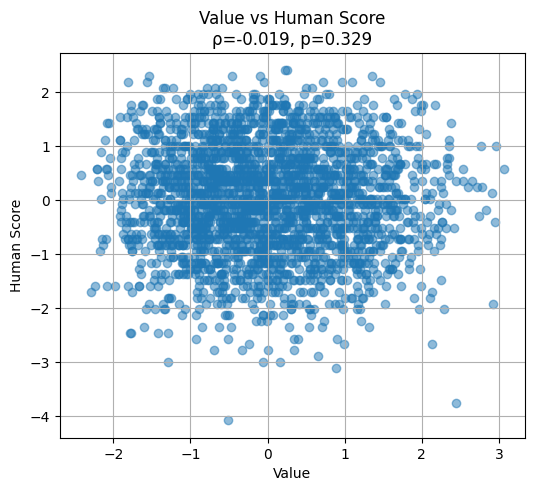

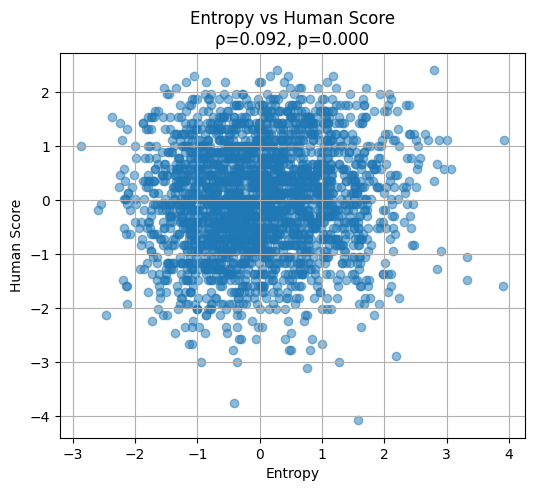

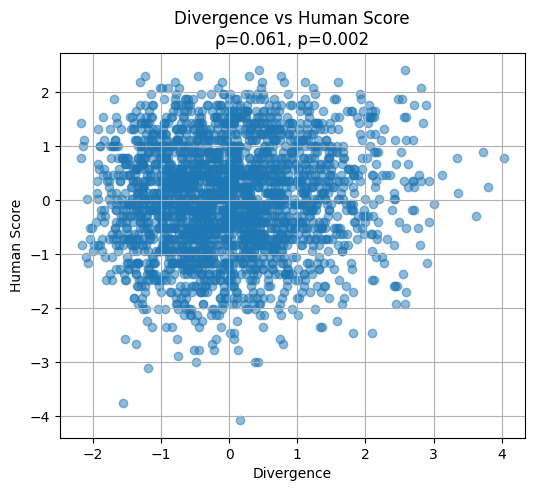

In [55]:
# Scatter plots: each model score vs LLM-judge score
scatter_plot(feature_df["value_z"], feature_df["avg_z"], "Value", "LLM-judge Score")
scatter_plot(feature_df["entropy_z"], feature_df["avg_z"], "Entropy", "LLM-judge Score")
scatter_plot(feature_df["div_z"], feature_df["avg_z"], "Divergence", "LLM-judge Score")

In [56]:
# Spearman matrix incl. the LLM-judge score
corr_matrix_full = feature_df[["value_z","entropy_z","div_z","avg_z"]].corr(method="spearman")
corr_matrix_full

,value_z,entropy_z,div_z,avg_z
value_z,1.000000,-0.114761,-0.508824,-0.019471
entropy_z,-0.114761,1.000000,0.139987,0.091621
div_z,-0.508824,0.139987,1.000000,0.061035
avg_z,-0.019471,0.091621,0.061035,1.000000


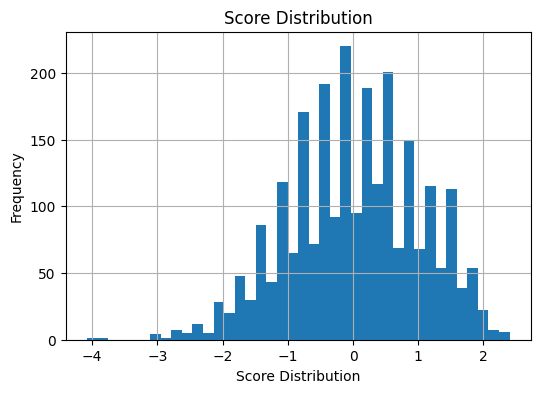

In [57]:
# Distribution of the LLM-judge score
plot_distribution(feature_df["avg_z"], "Score Distribution")

In [58]:
# Summary stats of LLM-judge score and the three model signals
summary_bench = feature_df[["avg_score","catboost_proba","entropy","divergence"]].describe()
summary_bench

,avg_score,catboost_proba,entropy,divergence
count,2519.000000,2519.000000,2519.000000,2519.000000
mean,6.815469,0.341634,3.392403,0.182582
std,0.771237,0.125373,0.385639,0.042061
min,3.666667,0.038101,2.286542,0.091290
25%,6.250000,0.247351,3.110573,0.152207
50%,6.833333,0.334044,3.367230,0.180016
75%,7.333333,0.429992,3.652834,0.208937
max,8.666667,0.725541,4.902291,0.351856


In [59]:
# Z-score the LLM-judge score on the clipped data
df_clip["avg_z"] = zscore(df_clip["avg_score"])

In [60]:
# Model vs LLM-judge correlations on the clipped data
for x, y in pairs_judge:
    rho, p = corr_with_p(df_clip[x], df_clip[y])
    print(f"{x} vs {y}: rho={rho:.3f}, p={p:.3f}")

value_z vs avg_z: rho=-0.019, p=0.328
entropy_z vs avg_z: rho=0.092, p=0.000
div_z vs avg_z: rho=0.061, p=0.002


In [61]:
# Z-score the four LLM-judge sub-ratings
cols = ["originality", "feasibility", "clarity", "fluency"]

for col in cols:
    feature_df[f"{col}_z"] = zscore(feature_df[col])

In [62]:
# Spearman matrix: model scores vs LLM-judge sub-ratings
corr_full = feature_df[[
    "value_z", "entropy_z", "div_z",
    "originality_z", "feasibility_z", "clarity_z", "fluency_z"
]].corr(method="spearman")

corr_full

,value_z,entropy_z,div_z,originality_z,feasibility_z,clarity_z,fluency_z
value_z,1.000000,-0.114761,-0.508824,-0.157082,0.173377,-0.100452,-0.022567
entropy_z,-0.114761,1.000000,0.139987,0.283675,0.000986,0.020813,0.015818
div_z,-0.508824,0.139987,1.000000,0.277522,-0.150866,0.186914,-0.007093
originality_z,-0.157082,0.283675,0.277522,1.000000,-0.262553,0.284652,0.096869
feasibility_z,0.173377,0.000986,-0.150866,-0.262553,1.000000,0.249661,0.046918
clarity_z,-0.100452,0.020813,0.186914,0.284652,0.249661,1.000000,0.002368
fluency_z,-0.022567,0.015818,-0.007093,0.096869,0.046918,0.002368,1.000000


In [63]:
# Hypothesis-driven score/sub-rating pairs to test
pairs = [
    # VALUE
    ("value_z", "feasibility_z"),
    ("value_z", "originality_z"),
    ("value_z", "clarity_z"),
    ("value_z", "fluency_z"),

    # ENTROPY
    ("entropy_z", "fluency_z"),
    ("entropy_z", "clarity_z"),

    # DIVERGENCE
    ("div_z", "originality_z"),
    ("div_z", "feasibility_z"),
]

In [64]:
# Correlations for those pairs (rho + bootstrap CI)
results_components = []

for x, y in pairs:
    rho, p = corr_with_p(feature_df[x], feature_df[y])
    ci_low, ci_high = bootstrap_ci(feature_df[x].values, feature_df[y].values)

    results_components.append({
        "pair": f"{x} vs {y}",
        "rho": rho,
        "p_value": p,
        "CI_low": ci_low,
        "CI_high": ci_high
    })

pd.DataFrame(results_components)

,pair,rho,p_value,CI_low,CI_high
0,value_z vs feasibility_z,0.173377,1.886622e-18,0.136055,0.211802
1,value_z vs originality_z,-0.157082,2.204515e-15,-0.195425,-0.119401
2,value_z vs clarity_z,-0.100452,4.373388e-07,-0.140106,-0.061410
3,value_z vs fluency_z,-0.022567,2.575470e-01,-0.063484,0.015948
4,entropy_z vs fluency_z,0.015818,4.274602e-01,-0.025896,0.051191
5,entropy_z vs clarity_z,0.020813,2.963943e-01,-0.017829,0.061812
6,div_z vs originality_z,0.277522,8.944772e-46,0.241892,0.311682
7,div_z vs feasibility_z,-0.150866,2.704260e-14,-0.187138,-0.112450


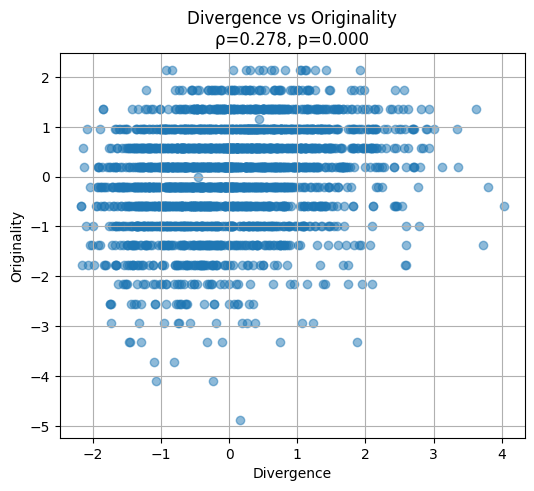

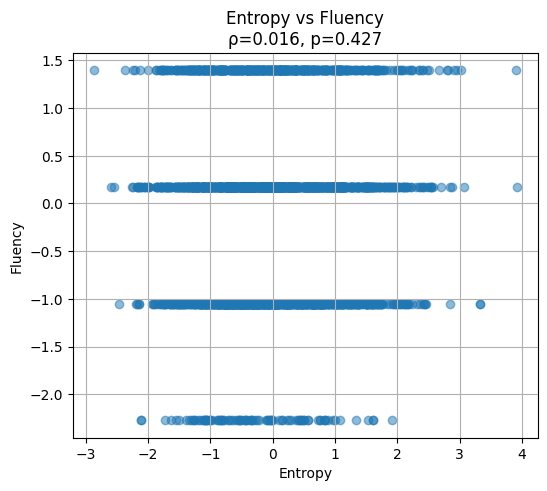

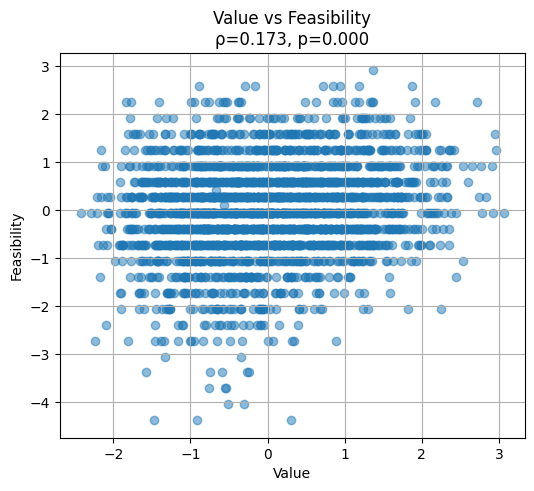

In [65]:
# Scatter plots for the key pairs
scatter_plot(feature_df["div_z"], feature_df["originality_z"], "Divergence", "Originality")
scatter_plot(feature_df["entropy_z"], feature_df["fluency_z"], "Entropy", "Fluency")
scatter_plot(feature_df["value_z"], feature_df["feasibility_z"], "Value", "Feasibility")

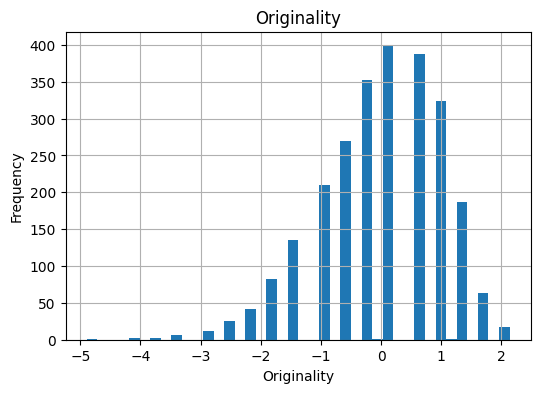

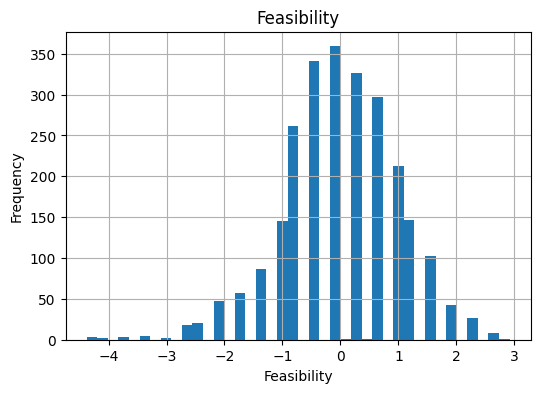

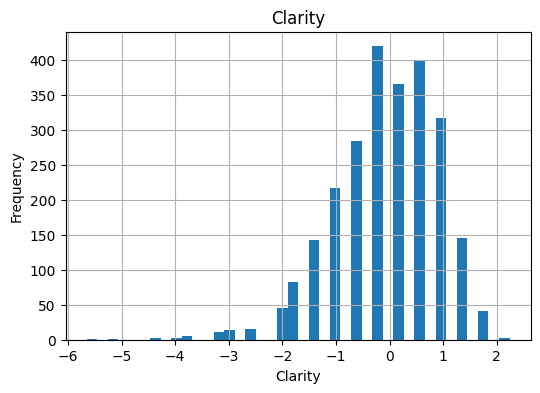

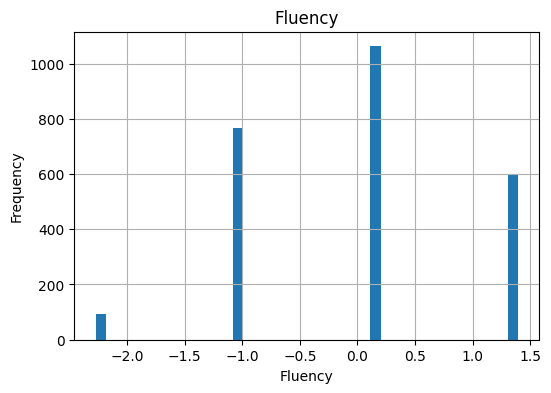

In [66]:
# Distributions of the four LLM-judge sub-ratings
plot_distribution(feature_df["originality_z"], "Originality")
plot_distribution(feature_df["feasibility_z"], "Feasibility")
plot_distribution(feature_df["clarity_z"], "Clarity")
plot_distribution(feature_df["fluency_z"], "Fluency")

In [67]:
# Top 10% thresholds
value_thresh = feature_df["catboost_proba"].quantile(0.90)
div_thresh = feature_df["divergence"].quantile(0.90)

print("Value threshold (top 10%):", value_thresh)
print("Divergence threshold (top 10%):", div_thresh)

Value threshold (top 10%): 0.5114967143530167
Divergence threshold (top 10%): 0.23859922600000008


In [68]:
# Top groups
top_value = feature_df[feature_df["catboost_proba"] >= value_thresh]
top_div = feature_df[feature_df["divergence"] >= div_thresh]

print("Top value count:", len(top_value))
print("Top divergence count:", len(top_div))

Top value count: 252
Top divergence count: 252


In [69]:
# Overlap
overlap = feature_df[
    (feature_df["catboost_proba"] >= value_thresh) &
    (feature_df["divergence"] >= div_thresh)
]

print("Overlap count:", len(overlap))
print("Overlap percentage:", len(overlap) / len(feature_df))

Overlap count: 0
Overlap percentage: 0.0


In [70]:
# High-value, low-divergence ideas
high_value_low_div = feature_df[
    (feature_df["catboost_proba"] >= value_thresh) &
    (feature_df["divergence"] <= feature_df["divergence"].quantile(0.25))
].sort_values(by="catboost_proba", ascending=False)

print("High value, low divergence:", len(high_value_low_div))

High value, low divergence: 156


In [71]:
# High-divergence, low-value ideas
high_div_low_value = feature_df[
    (feature_df["divergence"] >= div_thresh) &
    (feature_df["catboost_proba"] <= feature_df["catboost_proba"].quantile(0.25))
].sort_values(by="divergence", ascending=False)

print("High divergence, low value:", len(high_div_low_value))

High divergence, low value: 155


In [72]:
# Example high-value/low-divergence ideas
high_value_low_div_examples = high_value_low_div[[
    "idea", "catboost_proba", "divergence"
]].head()

high_value_low_div_examples

,idea,catboost_proba,divergence
1791,Here's a concise idea within the 100-word limi...,0.725541,0.125485
2349,Support Vector Machines (SVMs) are powerful ma...,0.712849,0.103298
1367,Background: Information retrieval involves fin...,0.711732,0.105433
2055,"Leveraging social network analysis, I propose ...",0.708586,0.129250
2299,Reinforcement learning (RL) has shown impressi...,0.705834,0.143062


In [73]:
# Their idea texts
high_value_low_div_examples["idea"].tolist()

['Here\'s a concise idea within the 100-word limit: **Background**: Reinforcement learning (RL) enables agents to learn from interactions with an environment by receiving rewards or penalties. However, in complex, real-world environments, designing effective reward functions can be challenging. **Idea**: "Adversarial Reward Shaping" - a novel approach to RL that leverages generative adversarial networks (GANs) to dynamically adapt and refine the reward function. The GAN\'s discriminator learns to distinguish between desired and undesired behaviors, while the generator creates new reward functions that encourage exploration and improvement. This approach can improve learning efficiency and adaptability in complex environments, addressing a long-standing challenge in RL.',
 "Support Vector Machines (SVMs) are powerful machine learning models for classification and regression tasks. Here's a novel idea: Develop an SVM-based framework that incorporates domain knowledge through custom kerne

In [74]:
# Example high-divergence/low-value ideas
high_div_low_value_examples = high_div_low_value[[
    "idea", "catboost_proba", "divergence"
]].head()

high_div_low_value_examples

,idea,catboost_proba,divergence
1404,Background: Plant microbiomes are vital for nu...,0.161065,0.351856
1851,Here's my idea: **Epigenetic Editing of Crop M...,0.181737,0.342287
125,# Targeted Microbiome Recovery Protocol Follow...,0.105373,0.323642
1199,Background: Antibiotic resistance is a growing...,0.104080,0.323083
827,**Idea: Smart Microbiome-based Biosensor for R...,0.131760,0.313940


In [75]:
# Their idea texts
high_div_low_value_examples["idea"].tolist()

['Background: Plant microbiomes are vital for nutrient uptake, yet current agriculture heavily relies on synthetic fertilizers, causing environmental damage. Idea: Engineer synthetic microbial consortia, inspired by natural soil microbiomes, to optimize nitrogen fixation and phosphorus solubilization in crop plants. These tailored consortia, designed for specific soil types and crops, will reduce synthetic fertilizer dependence, promoting sustainable and environmentally friendly agriculture. This approach leverages microbiome functionality for ecological and economically beneficial agricultural practices.',
 'Here\'s my idea: **Epigenetic Editing of Crop Memories** Background: Epigenetic modifications allow plants to "remember" environmental stresses, influencing their responses to future challenges. This phenomenon, known as "epigenetic memory," can be leveraged to improve crop resilience. Idea: Develop a CRISPR-Cas-based tool to selectively edit epigenetic marks associated with stres